# Student Performance EDA

ADEN AHMED MOHAMED — Cohort 1M DEVIS

County education office: identify support needs using the supplied synthetic seed-55 cohort; this is exploratory evidence, not an individual eligibility decision.

## Structure

**Grain:** one record per student in this synthetic cross-sectional cohort. student_id is an identifier, not a quantitative predictor; county, school_type and gender are nominal categories. attendance_rate is a continuous proportion rounded to two decimals, study_hours is a nonnegative continuous quantity rounded to one decimal, and math/english/science are integer-valued numeric scores on 0–100. No dates, sampling weights or student background controls are supplied.

In [1]:
from pathlib import Path
import runpy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

if not Path("student_performance.csv").exists():
    runpy.run_path("generate_data.py")
students = pd.read_csv("student_performance.csv")
Path("figures").mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)
display(students.head())
students.info()
display(students.dtypes.rename("dtype").to_frame())
score_columns = ["math", "english", "science"]
quality_checks = pd.Series({
    "missing_cells": int(students.isna().sum().sum()),
    "duplicate_rows": int(students.duplicated().sum()),
    "duplicate_student_ids": int(students.student_id.duplicated().sum()),
    "attendance_outside_0_1": int((~students.attendance_rate.between(0, 1)).sum()),
    "negative_study_hours": int(students.study_hours.lt(0).sum()),
    "subject_scores_outside_0_100": int((~students[score_columns].apply(lambda x: x.between(0, 100))).sum().sum()),
    "invalid_county": int((~students.county.isin(["Nairobi", "Kisumu", "Nakuru", "Mombasa", "Nyeri", "Turkana"])).sum()),
    "invalid_school_type": int((~students.school_type.isin(["Public", "Private"])).sum()),
    "invalid_gender": int((~students.gender.isin(["F", "M"])).sum()),
})
display(quality_checks.rename("rows_or_cells_affected").to_frame())
assert students.shape == (1200, 9)
assert quality_checks.eq(0).all()
print("No issues detected by these schema, range, missingness and uniqueness checks.")

,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.5,81.0,71.0,73.0
1,2,Nyeri,Private,M,0.97,8.5,100.0,86.0,90.0
2,3,Nyeri,Private,F,0.98,8.0,82.0,89.0,90.0
3,4,Turkana,Public,M,0.93,6.0,83.0,91.0,72.0
4,5,Kisumu,Private,F,0.67,6.1,76.0,69.0,62.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   student_id       1200 non-null   int64  
 1   county           1200 non-null   object 
 2   school_type      1200 non-null   object 
 3   gender           1200 non-null   object 
 4   attendance_rate  1200 non-null   float64
 5   study_hours      1200 non-null   float64
 6   math             1200 non-null   float64
 7   english          1200 non-null   float64
 8   science          1200 non-null   float64
dtypes: float64(5), int64(1), object(3)
memory usage: 84.5+ KB


,dtype
student_id,int64
county,object
school_type,object
gender,object
attendance_rate,float64
study_hours,float64
math,float64
english,float64
science,float64


,rows_or_cells_affected
missing_cells,0
duplicate_rows,0
duplicate_student_ids,0
attendance_outside_0_1,0
negative_study_hours,0
subject_scores_outside_0_100,0
invalid_county,0
invalid_school_type,0
invalid_gender,0


No issues detected by these schema, range, missingness and uniqueness checks.


**Assessment:** All supplied records pass the explicit checks; this does not independently prove source accuracy or representativeness. Large study-hour values are investigated below rather than automatically treated as data-entry errors. The hours variable’s recording interval is not defined in the generator, so interpretations use “recorded study hour” rather than assuming per day or per week.

## Univariate

Summarise every quantitative measurement with centre, spread and shape; report identifier coverage separately because its arithmetic mean is meaningless. Inspect every categorical variable with counts and shares. Define average_score as the arithmetic mean of three subjects and use pd.cut with left-closed bins: At Risk [0,60), Meeting [60,75), Exceeding [75,100]. Keep unrounded averages for classification, so fractional scores between 74 and 75 remain Meeting.

,count,mean,median,std_sample,min,q1,q3,IQR,max,skewness
attendance_rate,1200,0.804,0.820,0.119,0.330,0.730,0.900,0.17,1.0,-0.858
study_hours,1200,5.078,4.500,3.028,0.200,2.900,6.700,3.80,23.3,1.174
math,1200,71.889,72.000,10.858,37.000,65.000,79.000,14.00,100.0,0.102
english,1200,74.521,74.000,10.487,47.000,67.000,81.000,14.00,100.0,0.160
science,1200,69.612,69.000,12.022,35.000,61.000,78.000,17.00,100.0,0.107
average_score,1200,72.008,71.667,9.106,48.333,65.667,77.667,12.00,100.0,0.262


student_id: identifier only; unique = 1200 coverage = 1 to 1200


,count,share_pct
county,,
Turkana,191,15.92
Nyeri,203,16.92
Kisumu,208,17.33
Mombasa,212,17.67
Nakuru,202,16.83
Nairobi,184,15.33


,count,share_pct
school_type,,
Private,334,27.83
Public,866,72.17


,count,share_pct
gender,,
M,588,49.0
F,612,51.0


,count,share_pct
performance_band,,
At Risk,99,8.25
Meeting,672,56.00
Exceeding,429,35.75


Study-hour IQR fences: [-2.80, 12.40]; candidates: 29


,student_id,study_hours,average_score
94,95,15.2,95.666667
114,115,12.5,90.333333
119,120,15.0,86.000000
213,214,13.5,89.000000
271,272,17.1,89.333333
310,311,15.5,96.000000
364,365,15.3,95.333333
434,435,16.2,90.666667
502,503,14.6,91.333333
566,567,13.5,100.000000


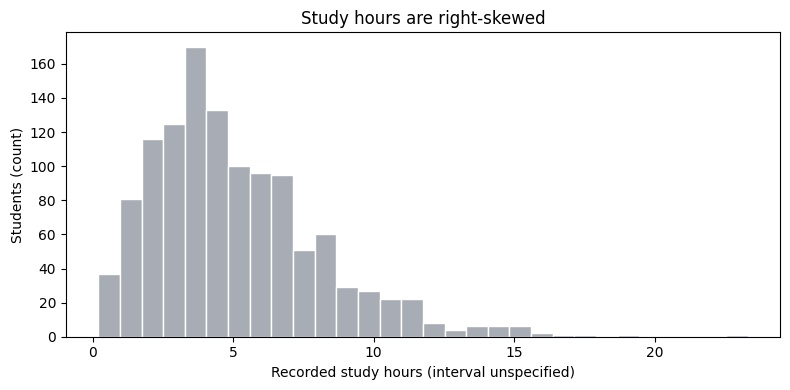

In [2]:
students["average_score"] = students[score_columns].mean(axis=1)
students["performance_band"] = pd.cut(
    students.average_score, bins=[-np.inf, 60, 75, np.inf],
    labels=["At Risk", "Meeting", "Exceeding"], right=False
)
# Boundary checks ensure exactly 60 is Meeting and 75 is Exceeding.
assert pd.cut(pd.Series([59.9, 60, 74.9, 75]), [-np.inf, 60, 75, np.inf],
              labels=["At Risk", "Meeting", "Exceeding"], right=False).tolist() == ["At Risk", "Meeting", "Meeting", "Exceeding"]
numeric_columns = ["attendance_rate", "study_hours", *score_columns, "average_score"]
numeric = students[numeric_columns]
numerical_summary = pd.DataFrame({
    "count": numeric.count(), "mean": numeric.mean(), "median": numeric.median(),
    "std_sample": numeric.std(ddof=1), "min": numeric.min(),
    "q1": numeric.quantile(.25), "q3": numeric.quantile(.75),
    "IQR": numeric.quantile(.75)-numeric.quantile(.25),
    "max": numeric.max(), "skewness": numeric.skew()
})
display(numerical_summary.round(3))
print("student_id: identifier only; unique =", students.student_id.nunique(),
      "coverage =", students.student_id.min(), "to", students.student_id.max())
for column in ["county", "school_type", "gender", "performance_band"]:
    counts = students[column].value_counts(sort=False)
    display(pd.DataFrame({"count": counts, "share_pct": counts / len(students) * 100}).round(2).rename_axis(column))
q1, q3 = students.study_hours.quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
study_outliers = students.loc[students.study_hours.lt(lower) | students.study_hours.gt(upper)]
print(f"Study-hour IQR fences: [{lower:.2f}, {upper:.2f}]; candidates: {len(study_outliers)}")
display(study_outliers[["student_id", "study_hours", "average_score"]])
ax = students.study_hours.plot(kind="hist", bins=30, color="#A8ADB5", edgecolor="white", figsize=(8, 4))
ax.set(title="Study hours are right-skewed", xlabel="Recorded study hours (interval unspecified)", ylabel="Students (count)")
ax.figure.tight_layout()
ax.figure.savefig("figures/eda_study_hours_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation:** Median study time is 4.5 hours versus mean 5.08; the positive skew makes the median a better typical value. The 29 IQR candidates exceed 12.40 hours; the generator uses a gamma distribution, so high values can be valid and are retained. Attendance is concentrated at high values and scores can reach the upper boundary because the generator clips them at 100.

Saved figure: `figures/eda_study_hours_histogram.png`.

## Bivariate

Calculate Pearson and Spearman matrices for all quantitative measurements, excluding the numeric student identifier. Rank correlations with average_score by absolute strength and distinguish the mechanically related subject components from potential support factors. Compare gender/school/county means and At Risk county counts alongside shares.

Pearson correlation matrix


,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.000,-0.029,0.300,0.327,0.260,0.359
study_hours,-0.029,1.000,0.560,0.624,0.550,0.704
math,0.300,0.560,1.000,0.559,0.459,0.814
english,0.327,0.624,0.559,1.000,0.502,0.827
science,0.260,0.550,0.459,0.502,1.000,0.815
average_score,0.359,0.704,0.814,0.827,0.815,1.000


Spearman correlation matrix


,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.000,-0.029,0.295,0.310,0.240,0.344
study_hours,-0.029,1.000,0.519,0.579,0.509,0.659
math,0.295,0.519,1.000,0.527,0.436,0.794
english,0.310,0.579,0.527,1.000,0.470,0.805
science,0.240,0.509,0.436,0.470,1.000,0.799
average_score,0.344,0.659,0.794,0.805,0.799,1.000


,r_with_average_score
english,0.827193
science,0.815435
math,0.814043


,size,mean,median,std
gender,,,,
F,612,72.097,71.667,9.174
M,588,71.914,71.333,9.041


,size,mean,median,std
school_type,,,,
Private,334,76.011,75.333,8.119
Public,866,70.463,69.667,8.999


,size,mean,median,std
county,,,,
Kisumu,208,73.067,72.500,9.537
Mombasa,212,72.170,72.167,8.354
Nairobi,184,71.958,72.167,9.347
Nakuru,202,71.837,70.833,8.982
Nyeri,203,71.939,71.333,9.134
Turkana,191,70.974,70.000,9.279


,students,at_risk_count,at_risk_share,mean_score
county,,,,
Nairobi,184,17,0.0924,71.9583
Mombasa,212,19,0.0896,72.1698
Nyeri,203,18,0.0887,71.9392
Kisumu,208,17,0.0817,73.0673
Turkana,191,15,0.0785,70.9738
Nakuru,202,13,0.0644,71.8366


Highest At Risk share: Nairobi


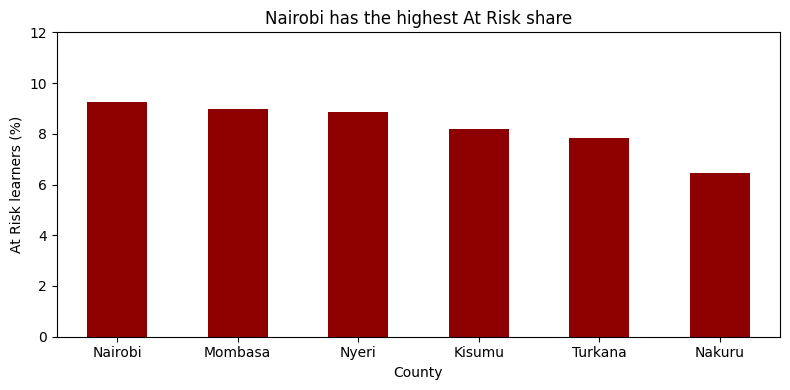

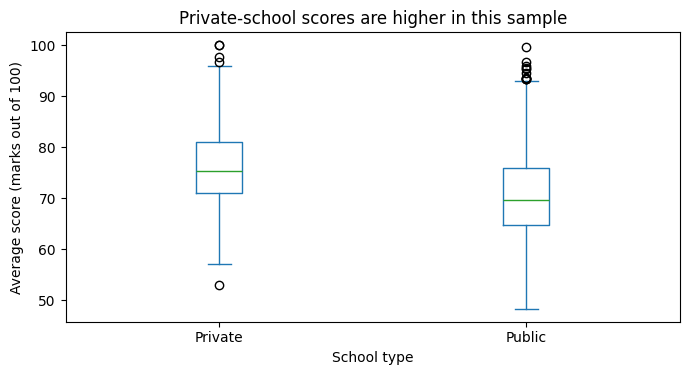

In [3]:
pearson = students[numeric_columns].corr(method="pearson")
spearman = students[numeric_columns].corr(method="spearman")
print("Pearson correlation matrix")
display(pearson.round(3))
print("Spearman correlation matrix")
display(spearman.round(3))
strongest_three = pearson.average_score.drop("average_score").sort_values(key=abs, ascending=False).head(3)
display(strongest_three.rename("r_with_average_score").to_frame())
for column in ["gender", "school_type", "county"]:
    display(students.groupby(column).average_score.agg(["size", "mean", "median", "std"]).round(3))
county_summary = students.assign(at_risk=students.average_score.lt(60)).groupby("county").agg(
    students=("student_id", "size"), at_risk_count=("at_risk", "sum"),
    at_risk_share=("at_risk", "mean"), mean_score=("average_score", "mean")
).sort_values("at_risk_share", ascending=False)
display(county_summary.round(4))
print("Highest At Risk share:", county_summary.index[0])
ax = (county_summary.at_risk_share * 100).plot(kind="bar", color="#8E0000", figsize=(8, 4))
ax.set(title="Nairobi has the highest At Risk share", xlabel="County", ylabel="At Risk learners (%)", ylim=(0, 12))
ax.tick_params(axis="x", rotation=0)
ax.figure.tight_layout()
ax.figure.savefig("figures/eda_county_risk_bar.png", dpi=160, bbox_inches="tight")
plt.show()
ax = students.pivot(columns="school_type", values="average_score").plot(kind="box", figsize=(7, 4))
ax.set(title="Private-school scores are higher in this sample", xlabel="School type", ylabel="Average score (marks out of 100)")
ax.figure.suptitle("")
ax.figure.tight_layout()
ax.figure.savefig("figures/eda_school_type_boxplot.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation:** The three strongest Pearson relationships with average_score are English (0.827), Science (0.815) and Math (0.814). They are positive but partly mechanical because those three scores define the average; they are not three independent explanations of performance. Among background measurements, study_hours (0.704) is more strongly associated with the average than attendance_rate (0.359). Nairobi’s At Risk share is 9.24% (17/184), while Mombasa’s is 8.96% but has 19 learners; a county budget should consider both prevalence and counts, not just rankings.

Saved figures: `figures/eda_county_risk_bar.png` and `figures/eda_school_type_boxplot.png`; the latter uses pandas’ .plot(kind="box").

## Multivariate

Attendance bands are below 70%, 70–85% inclusive and above 85%; ties at 70% enter the middle band and 85% remains there. Study-hour quartiles come from pd.qcut and account for repeated rounded values. Build means and cell counts by school type for each segmentation, then a joint pivot to check attendance and study time together; these are descriptive comparisons, not causal adjustment.

Observed study-hour quartile boundaries:


,min,max,size
study_quartile,,,
Q1,0.2,2.9,311
Q2,3.0,4.5,302
Q3,4.6,6.7,288
Q4,6.8,23.3,299


attendance_band mean scores and group sizes


school_type,Private,Public,Private_minus_Public
attendance_band,,,
Below 70%,71.055,64.852,6.203
70–85%,75.444,69.563,5.881
Above 85%,78.987,73.957,5.030


school_type,Private,Public
attendance_band,,
Below 70%,61,146
70–85%,144,386
Above 85%,129,334


study_quartile mean scores and group sizes


school_type,Private,Public,Private_minus_Public
study_quartile,,,
Q1,69.512,63.821,5.691
Q2,74.919,67.122,7.797
Q3,76.179,71.181,4.998
Q4,83.646,80.057,3.590


school_type,Private,Public
study_quartile,,
Q1,84,227
Q2,86,216
Q3,82,206
Q4,82,217


school_type                     Private  Public  Private_minus_Public
attendance_band study_quartile                                       
Below 70%       Q1               62.643  58.019                 4.624
                Q2               69.611  60.259                 9.352
                Q3               73.429  65.909                 7.519
                Q4               77.143  74.033                 3.110
70–85%          Q1               68.374  63.177                 5.197
                Q2               74.419  66.721                 7.698
                Q3               74.798  69.756                 5.042
                Q4               83.000  79.858                 3.142
Above 85%       Q1               73.126  66.824                 6.302
                Q2               77.295  70.921                 6.374
                Q3               79.869  75.012                 4.857
                Q4               87.655  83.100                 4.556

school_type                     Private  Public
attendance_band study_quartile                 
Below 70%       Q1                   14      36
                Q2                   12      36
                Q3                   21      33
                Q4                   14      41
70–85%          Q1                   33     100
                Q2                   39     104
                Q3                   33      93
                Q4                   39      89
Above 85%       Q1                   37      91
                Q2                   35      76
                Q3                   28      80
                Q4                   29      87

average_score = 61.2595 + 2.1166 × study_hours; R² = 0.4954


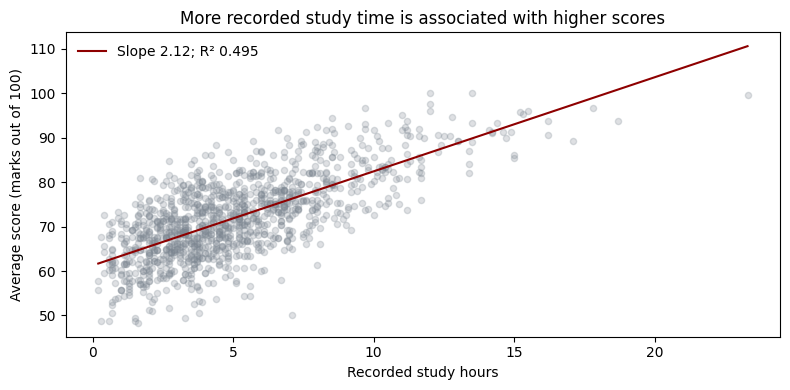

In [4]:
students["attendance_band"] = pd.cut(students.attendance_rate,
    bins=[-np.inf, .70, .850000001, np.inf], right=False,
    labels=["Below 70%", "70–85%", "Above 85%"])
students["study_quartile"] = pd.qcut(students.study_hours, 4, labels=["Q1", "Q2", "Q3", "Q4"])
print("Observed study-hour quartile boundaries:")
display(students.groupby("study_quartile", observed=True).study_hours.agg(["min", "max", "size"]))
for dimension in ["attendance_band", "study_quartile"]:
    means = students.pivot_table(index=dimension, columns="school_type", values="average_score", aggfunc="mean", observed=True)
    counts = students.pivot_table(index=dimension, columns="school_type", values="student_id", aggfunc="count", observed=True)
    means["Private_minus_Public"] = means.Private - means.Public
    print(dimension, "mean scores and group sizes")
    display(means.round(3))
    display(counts)
joint_means = students.pivot_table(index=["attendance_band", "study_quartile"], columns="school_type", values="average_score", aggfunc="mean", observed=True)
joint_counts = students.pivot_table(index=["attendance_band", "study_quartile"], columns="school_type", values="student_id", aggfunc="count", observed=True)
joint_means["Private_minus_Public"] = joint_means.Private - joint_means.Public
display(joint_means.round(3))
display(joint_counts)
x, y = students.study_hours.to_numpy(), students.average_score.to_numpy()
slope, intercept = np.polyfit(x, y, 1)
fitted = slope*x + intercept
r_squared = 1 - np.square(y-fitted).sum()/np.square(y-y.mean()).sum()
print(f"average_score = {intercept:.4f} + {slope:.4f} × study_hours; R² = {r_squared:.4f}")
ax = students.plot(kind="scatter", x="study_hours", y="average_score", alpha=.25, color="#7D8792", figsize=(8, 4))
line_x = np.array([x.min(), x.max()])
ax.plot(line_x, intercept+slope*line_x, color="#8E0000", label=f"Slope {slope:.2f}; R² {r_squared:.3f}")
ax.set(xlabel="Recorded study hours", ylabel="Average score (marks out of 100)", title="More recorded study time is associated with higher scores")
ax.legend(frameon=False)
ax.figure.tight_layout()
ax.figure.savefig("figures/eda_study_score_trend.png", dpi=160, bbox_inches="tight")
plt.show()

**Trend interpretation:** Each additional recorded study hour is associated with an average **2.117-mark** increase in the fitted score, and the single-predictor fit explains **49.54%** of in-sample score variation. **Prediction limitation:** This cross-sectional, capped synthetic outcome and unadjusted line cannot establish a study-time intervention effect or safely predict outside the observed 0.2–23.3 hours. Saved figure: `figures/eda_study_score_trend.png`.

The private-school advantage remains in each attendance band and study quartile; cell counts and the joint table are shown so narrow or unstable comparisons remain visible. School type has a built-in six-mark coefficient in the generator; this is not real-world evidence that private schooling itself causes a gain.

## Hypotheses

1. **Lower attendance is associated with a higher At Risk share:** compare risk shares and counts within the three bands.
2. **The private–public gap persists when comparing similar observed study time and attendance:** inspect the joint pivots rather than interpreting the headline gap as causal.
3. **The study-time association flattens at high hours because scores are capped:** compare a descriptive fit within the IQR range with the full-range fit.

These are exploratory hypotheses suggested by the generated data, not pre-registered tests; no p-values or causal effects are claimed.

In [5]:
risk_by_attendance = students.assign(at_risk=students.average_score.lt(60)).groupby("attendance_band", observed=True).agg(
    learners=("student_id", "size"), at_risk=("at_risk", "sum"), risk_share=("at_risk", "mean")
)
display(risk_by_attendance.round(4))
print("Joint cells with Private mean above Public:", joint_means.Private.gt(joint_means.Public).sum(), "of", len(joint_means))
core = students.loc[students.study_hours.between(lower, upper)]
core_slope, _ = np.polyfit(core.study_hours, core.average_score, 1)
print(f"Full slope: {slope:.3f}; IQR-range slope: {core_slope:.3f}")
print("Clipping, noise and subgroup composition can all affect the line; sensitivity is descriptive.")

,learners,at_risk,risk_share
attendance_band,,,
Below 70%,207,50,0.2415
70–85%,530,37,0.0698
Above 85%,463,12,0.0259


Joint cells with Private mean above Public: 12 of 12
Full slope: 2.117; IQR-range slope: 2.185
Clipping, noise and subgroup composition can all affect the line; sensitivity is descriptive.


## Findings

1. 99 of 1,200 learners (8.25%) score below 60 and are classified At Risk.
2. Nairobi has the highest At Risk share at 9.24% (17 of 184), while Mombasa has the largest count at 19.
3. Private-school learners average 76.01 against 70.46 in Public schools, a 5.55-mark association that persists within attendance bands and study-hour quartiles.
4. Study hours correlate with average_score at r=0.704; the fitted slope is 2.117 marks per recorded study hour and R²=0.495, without implying causation.
5. Study hours are right-skewed (skewness 1.17), with median 4.5, mean 5.08 and 29 upper-IQR review candidates, which are retained rather than presumed invalid.

## Recommendations

1. Target initial outreach using verified **individual low scores plus attendance below 70%**, offering attendance follow-up, catch-up support and monitoring; treat these as screening signals and check the learner’s situation before deciding support. Report numbers and risk shares together so Nairobi’s highest share does not obscure Mombasa’s largest At Risk count.
2. Pilot structured study support and tutoring in public schools with low-score learners, then evaluate changes using baseline and follow-up scores and a fair comparison group; the 5.55-mark school-type association and study-time correlation justify investigation, not a promise that switching schools or adding an hour will produce the fitted gain.

## Limitations

The 1,200 records are synthetic, unweighted and cross-sectional, so county rankings are not population estimates or causal evidence. Attendance, study time and school type were deliberately used to construct scores, which are rounded and capped at 100; component correlations with their own average are mathematically coupled. Household income, prior attainment, disability, teaching resources and family circumstances are absent. Hours have no specified daily/weekly interval, self-report validity is unknown, quartile ties create uneven groups, and small joint segments warrant caution. Statistical outliers are not verified errors. The fitted R² is in-sample, with no holdout validation; it is unsuitable for individual funding decisions or extrapolation.